---
title: "ELSOC: persistencia y cambios de consumo regular"
subtitle: "Tres intervalos observados: 2016–2018, 2018–2021 y 2021–2023"
author: "MiCSim · FONDECYT 1240138"
lang: es
format:
  html:
    theme: journal
    css: [_lib/styles.css, _lib/prediction_metrics_compact.css]
    toc: true
    toc-location: left
    toc-depth: 2
    number-sections: false
    code-fold: true
    code-summary: "Ver código R"
    code-tools: true
    embed-resources: true
    self-contained: true
    html-math-method: mathml
execute:
  echo: true
  warning: false
  error: false
---

**Lectura rápida:** los tres enlaces son analizables y mantienen cerca del 70% de respuestas S09 iguales. El balance de cambio de frecuencia varía entre períodos. Son estimaciones exploratorias **sin ponderar**, con intervalos reales diferentes y cambios de modalidad.

S09/S10 **no constituyen AUDIT**. No regular no es abstinencia; el salto S10 no es frecuencia cero. La matriz de frecuencia incluye únicamente regulares en ambos extremos con frecuencia válida. No se calculan gramos/día ni HED.

Este notebook nuevo calcula los dos pares anteriores y reutiliza íntegramente las estimaciones 2021→2023 ya verificadas. No ejecuta ni modifica motores o notebooks originales. [Métodos y decisiones](__andres_control/elsoc_2021_2023_exploration/INTERVALS.md) · [Tabla comparativa CSV](__andres_control/elsoc_2021_2023_exploration/intervals/interval_comparison.csv).

> **Preparado para la próxima ejecución:** los scripts leen el SAV cifrado en `_elsoc/` mediante `acc_data()`. Los cinco PDF de origen están cifrados en `_elsoc/docs/elsoc_documentacion_pdf.tar.xz.enc`; acceso e inventario en el [mapa interno](_elsoc/README.md). Las salidas visibles proceden de la ejecución anterior. Por indicación del usuario no se ejecutó ni renderizó el notebook tras esta última preparación; el HTML existente no incorpora este aviso.

## Objetivo y reproducibilidad

Explorar si se repiten la persistencia y la dirección de cambio sin imponer estabilidad. El análisis enlaza extremos por persona, con edad 18–65 en cada origen, y mantiene cada intervalo separado. Comprobaciones: códigos y rutas, ID único, flujos, sumas de matrices, reproducción del último par y conservación por hash de sus tablas.


In [1]:
#| label: elsoc-analysis
.t0 <- Sys.time()
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL","English_United States.utf8"))
elsoc_root <- normalizePath(getwd(),winslash="/",mustWork=TRUE)
while (!file.exists(file.path(elsoc_root,".acc_root")) && dirname(elsoc_root)!=elsoc_root) elsoc_root<-dirname(elsoc_root)
stopifnot(file.exists(file.path(elsoc_root,".acc_root")))
source(file.path(elsoc_root,"_tools","acc_data.R"))
elsoc_root<-acc_root(elsoc_root)
elsoc_base<-file.path(elsoc_root,"__andres_control","elsoc_2021_2023_exploration")
stopifnot(all(vapply(c("haven","tidyselect","ggplot2","IRdisplay","htmltools","knitr"),requireNamespace,logical(1),quietly=TRUE)))
source(file.path(elsoc_base,"extend_intervals.R"),local=new.env(parent=globalenv()))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Two new intervals computed; 2021-2023 estimates reused. Elapsed 0.13 minutes.



Elapsed: 0.14 minutes


In [2]:
#| label: elsoc-display
.t0 <- Sys.time()
read_table<-function(name) utils::read.csv(file.path(elsoc_base,"intervals",paste0(name,".csv")),stringsAsFactors=FALSE)
show_table<-function(x,caption,digits=1) IRdisplay::display_html(as.character(htmltools::div(style="overflow-x:auto;max-height:660px;overflow-y:auto",htmltools::HTML(knitr::kable(x,format="html",digits=digits,row.names=FALSE,caption=caption)))))
pct<-function(x)ifelse(is.na(x),"—",sprintf("%.1f%%",100*x))
ci<-function(x)paste0(pct(x$estimate),ifelse(is.na(x$lower)," [sin IC]",paste0(" [",pct(x$lower),"; ",pct(x$upper),"]")),ifelse(x$small_origin," *",""))
group_label<-function(x){x<-gsub("Men_","Hombres ",x,fixed=TRUE);x<-gsub("Women_","Mujeres ",x,fixed=TRUE);x<-gsub("Education_Basic_or_less","Básica o menos",x,fixed=TRUE);x<-gsub("Education_Secondary","Media",x,fixed=TRUE);x<-gsub("Education_Higher","Superior",x,fixed=TRUE);gsub("Education_Unknown","Desconocida",x,fixed=TRUE)}
matrix_data<-read_table("transition_matrices_unweighted")
change_data<-read_table("change_summary_unweighted")
comparison<-read_table("interval_comparison")
flow<-read_table("sample_flow")
periods<-unique(comparison$interval)
show_plot<-function(p,name,width=10,height=5.5){folder<-file.path(elsoc_base,"intervals");ggplot2::ggsave(file.path(folder,paste0(name,".png")),p,width=width,height=height,dpi=170,bg="white");ggplot2::ggsave(file.path(folder,paste0(name,".pdf")),p,width=width,height=height,device=grDevices::cairo_pdf,bg="white");IRdisplay::display_png(file=file.path(folder,paste0(name,".png")))}
plot_theme<-function()ggplot2::theme_minimal(base_size=12)+ggplot2::theme(panel.grid.minor=ggplot2::element_blank(),legend.position="bottom",plot.title=ggplot2::element_text(face="bold"))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Elapsed: 0.00 minutes


## Comparación de los tres intervalos

La duración se calcula en los enlaces tras controles con fechas individuales. Los N S09 y S10 son denominadores distintos; los porcentajes S10 no describen a todo el panel.

In [3]:
#| label: elsoc-comparison
.t0 <- Sys.time()
z<-comparison[comparison$sample=="All",]
show_table(data.frame(Intervalo=z$interval,Inicial=z$n_baseline,Reentrevista=z$n_reinterviewed,Enlaces=z$n_primary,N_S09=z$n_s09,N_S10=z$n_s10,Mediana_años=round(z$median_years,3),Rango_años=sprintf("%.3f–%.3f",z$min_years,z$max_years)),"Tamaños y duración real")
show_table(data.frame(Intervalo=z$interval,S09_igual=pct(z$s09_same),Regular_a_regular=pct(z$regular_stay),No_regular_a_no_regular=pct(z$nonregular_stay),S10_igual=pct(z$s10_same),S10_aumenta=pct(z$s10_increase),S10_disminuye=pct(z$s10_decrease)),"Estabilidad y dirección; probabilidades S09 de permanencia condicionadas por origen")
net<-read_table("paired_regular_share_change");net<-net[net$group=="All",]
show_table(data.frame(Intervalo=net$interval,N=net$n,Regular_origen=net$regular_origin,Regular_destino=net$regular_destination,Cambio_pp=round(100*net$difference,2),IC95_pp=sprintf("[%.2f; %.2f]",100*net$lower,100*net$upper)),"Cambio pareado de proporción regular, sin inferencia poblacional")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Intervalo,Inicial,Reentrevista,Enlaces,N_S09,N_S10,Mediana_años,Rango_años
2016-2018,2562,1937,1917,1888,438,2.0,1.736–2.283
2018-2021,3221,2286,2281,2261,631,2.4,2.190–2.872
2021-2023,2300,1815,1802,1796,502,2.9,2.442–3.253


Intervalo,S09_igual,Regular_a_regular,No_regular_a_no_regular,S10_igual,S10_aumenta,S10_disminuye
2016-2018,69.7%,64.6%,72.5%,33.1%,29.7%,37.2%
2018-2021,71.4%,67.3%,74.4%,31.4%,40.3%,28.4%
2021-2023,71.0%,65.1%,75.5%,32.3%,32.1%,35.7%


Intervalo,N,Regular_origen,Regular_destino,Cambio_pp,IC95_pp
2016-2018,1888,690,775,4.5,[1.80; 7.45]
2018-2021,2261,942,972,1.3,[-0.99; 3.60]
2021-2023,1796,774,754,-1.1,[-3.60; 1.26]


Elapsed: 0.00 minutes


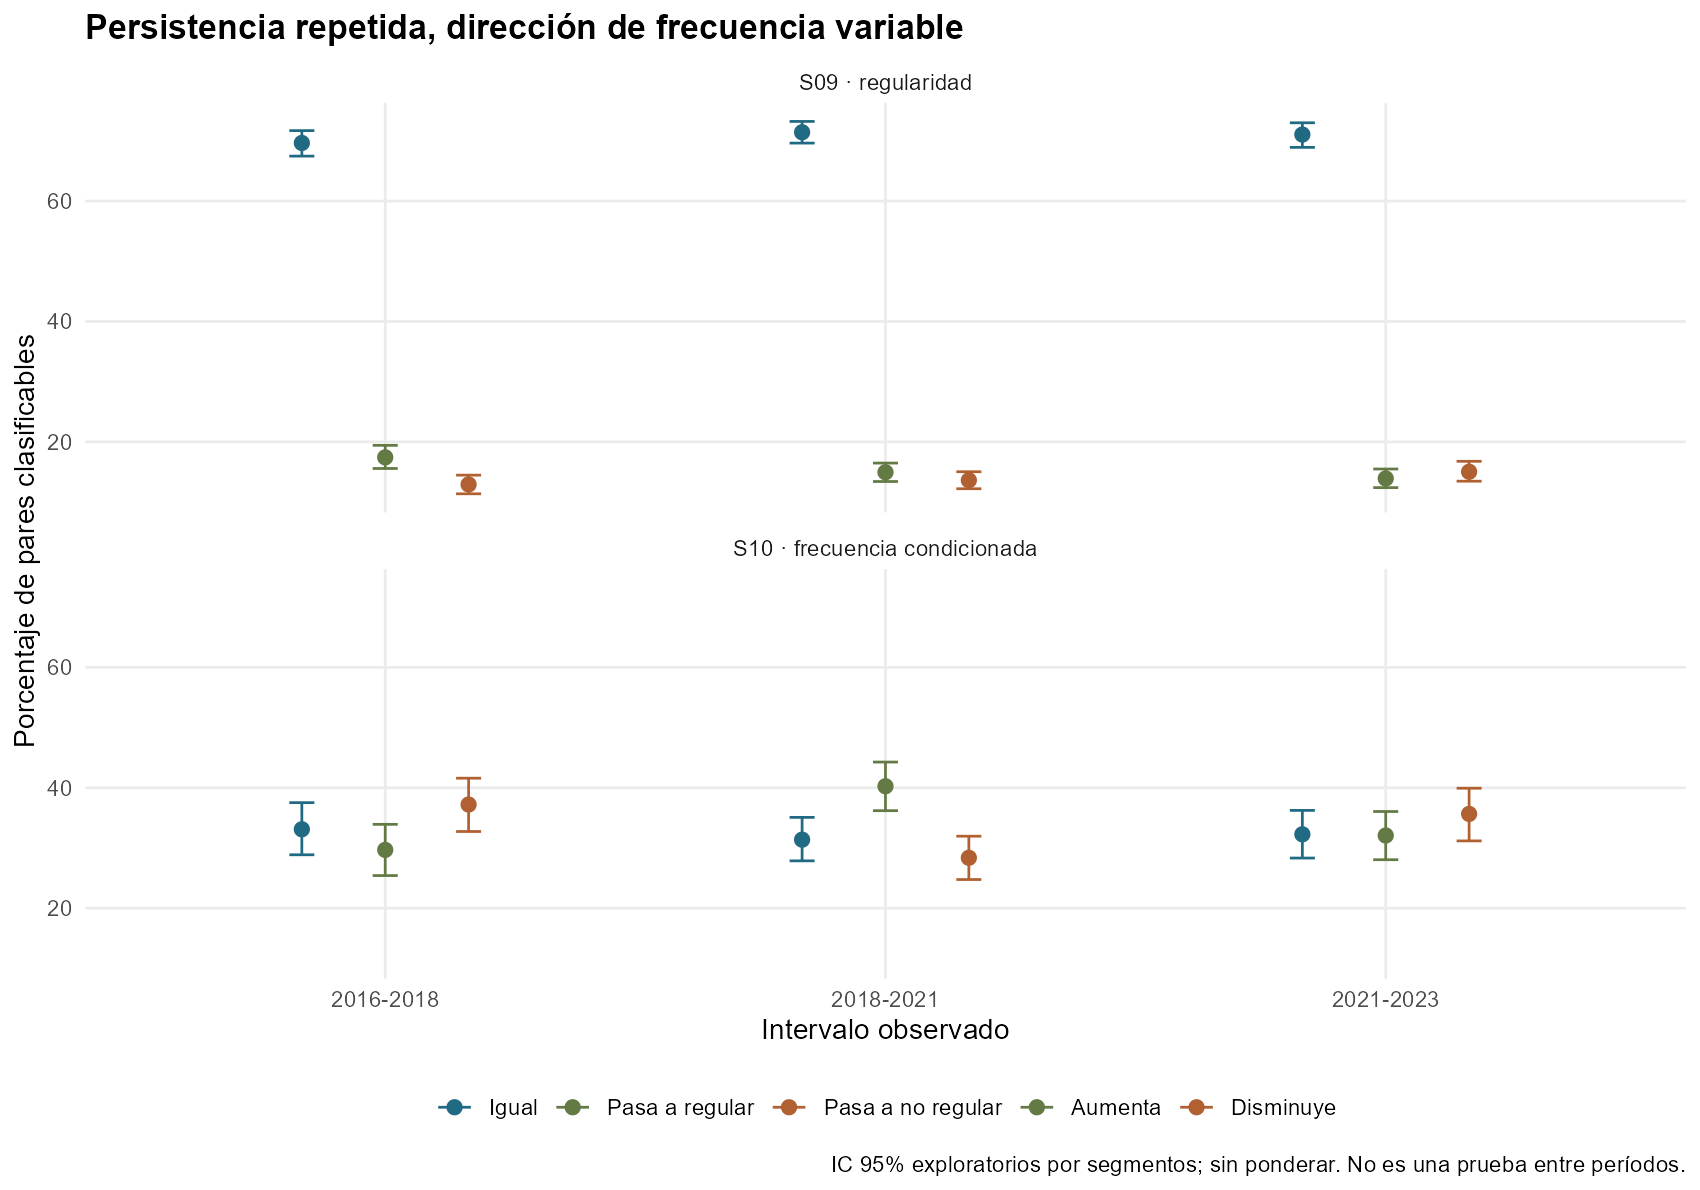

Elapsed: 0.01 minutes


In [4]:
#| label: elsoc-comparison-plot
.t0 <- Sys.time()
z<-change_data[change_data$group=="All",]
z$Indicador<-ifelse(z$item=="s09","S09 · regularidad","S10 · frecuencia condicionada")
z$Cambio<-factor(z$event,levels=c("same","entry_regular","exit_regular","increase","decrease"),labels=c("Igual","Pasa a regular","Pasa a no regular","Aumenta","Disminuye"))
p<-ggplot2::ggplot(z,ggplot2::aes(x=interval,y=100*estimate,color=Cambio,group=Cambio))+ggplot2::geom_point(position=ggplot2::position_dodge(width=.5),size=2.5)+ggplot2::geom_errorbar(ggplot2::aes(ymin=100*lower,ymax=100*upper),position=ggplot2::position_dodge(width=.5),width=.15)+ggplot2::facet_wrap(~Indicador,ncol=1)+ggplot2::scale_color_manual(values=c("#216A83","#637A44","#B16031","#637A44","#B16031"),drop=TRUE)+ggplot2::labs(x="Intervalo observado",y="Porcentaje de pares clasificables",color=NULL,title="Persistencia repetida, dirección de frecuencia variable",caption="IC 95% exploratorios por segmentos; sin ponderar. No es una prueba entre períodos.")+plot_theme()
show_plot(p,"comparison",height=7)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


## Instrumentos y comparabilidad

| Ola / variables originales | Contenido y referencia | Códigos, universo y salto | Modalidad y juicio de comparabilidad |
|---|---|---|---|
| 2016: `s09_w01`, `s10_w01` | S09 regularidad declarada, sin período explícito. S10 días/semana en el último mes. | S09: 1 sí, 2 no. S10: 1 <1 día, 2=1, 3=2, 4=3, 5=4, 6=5, 7=6, 8=7. S10 solo S09=1; 2/NS/NR omiten frecuencia. | M1, CAPI. Cotejo previo del cuestionario y nuevo cotejo de diccionario/metadatos. El PDF 2016 no pudo descargarse nuevamente en esta ampliación. |
| 2018: `s09_w03`, `s10_w03` | Mismas preguntas y referencias. | Mismos códigos y universo; formularios M1/M2 revisados, S09=2/NS/NR pasa S11. | M1 y refresco M2, CAPI. Contenido directamente comparable con 2016; composición distinta al incorporar refresco. |
| 2021: `s09_w05`, `s10_w05` | Mismas preguntas, alcohol en llamado A. | Misma escala/filtro; instrucciones explícitas de leer alternativas. | M1/M2, CATI en dos llamados. Comparable en contenido, con efecto de modo posible; no afirmar invariancia de medición. Portadas que dicen 2020 no reemplazan fechas de terreno. |
| 2023: `s09_w07`, `s10_w07` | Repetición documentada en CAPI M1/M2. | Mismos códigos y ruta S10, respuestas válidas verificadas en ambas muestras. | Operativo mixto CAPI/CATI; falta identificar modo individual y cotejar instrumento CATI. Muestra no identifica modalidad. |

Preguntas del listado oficial local: S09 «¿Consume usted regularmente bebidas alcohólicas como cerveza, vino, pisco u otros licores?»; S10 «En el último mes, ¿cuántos días a la semana consumió alguna bebida alcohólica?». Transformación común interna: conservar S09 1/2 y S10 ordinal 1–8. Se pierde la posibilidad de observar cambios entre entrevistas, no información mediante colapsos: las categorías originales se mantienen. Código S10=1 no se convierte en cero ni en un punto medio.

En las cuatro olas se verificaron códigos y respuestas: no hay S10 válida con S09=2. Se conservan −999 NR, −888 NS, −777 error técnico, −666 encuesta incompleta y faltantes del sistema en [etiquetas](__andres_control/elsoc_2021_2023_exploration/intervals/value_labels.csv), [conteos](__andres_control/elsoc_2021_2023_exploration/intervals/raw_code_counts.csv) y [rutas](__andres_control/elsoc_2021_2023_exploration/intervals/s10_routing.csv). Los dos últimos códigos especiales están documentados pero no se presupone que ocurran en todas las olas. Respuesta desconocida de S09 no permite inferir no regularidad; falta de entrevista no es falta de ítem. S10 excluye de su análisis las entradas y salidas de regularidad: su selección cambia entre períodos.

## Flujo, filtros y seguimiento

Se usa `idencuesta` único del combinado ancho, con `ola_wXX=1` para participación y 2 para ausencia. La presencia coincide con `cuestion_completo_wXX` informado. Se enlazan exclusivamente los extremos de cada par, sin exigir olas intermedias ni panel balanceado. Se emplea la versión ancha actual: el manual documenta correcciones históricas de casos falsificados y pesos; no se mezclaron entregas antiguas. Archivo, MD5 y contexto de reproducibilidad: [README previo](__andres_control/elsoc_2021_2023_exploration/README.md).

Filtros constantes: edad 18–65 en origen, sexo válido 1/2 coincidente entre extremos, fechas interpretables y ordenadas dentro de los años observados de terreno, edad de destino 18–110. No se restringe destino a 65 años. Se conservan cuestionarios incompletos cuando ambos ítems requeridos son válidos; sensibilidad a completos disponible. Las edades de origen definen siempre 18–29, 30–44, 45–59 y 60–65. Hay 51, 32 y 0 participantes de 18–19 en los respectivos dominios iniciales; en el último par la banda 18–29 contiene efectivamente 20–29.

| Intervalo | Sin reentrevista / dominio basal | Discordancias de sexo excluidas | Fechas inválidas adicionales | S09 faltante tras controles | Regulares en ambos / S10 válido | Ausencia intermedia y retorno |
|---|---|---:|---:|---:|---|---:|
| 2016→2018 | 625/2.562 = 24,4% | 20 | 0 | 29 | 446 / 438 | 103 (ausentes 2017) |
| 2018→2021 | 935/3.221 = 29,0% | 5 | 0 | 20 | 634 / 631 | 113 (ausentes 2019) |
| 2021→2023 | 485/2.300 = 21,1% | 2 | 11 | 6 | 504 / 502 | 174 (ausentes 2022) |

No hay descartes adicionales por edad de destino fuera del rango plausible. Una discordancia de sexo no prueba error de identidad; se aplica el mismo control del análisis anterior. Ausencia en destino no acredita muerte ni salida permanente. Los retornos sí se identifican por trayectoria observada, sin exigir que respondan en la ola intermedia. [Flujos completos M1/M2](__andres_control/elsoc_2021_2023_exploration/intervals/sample_flow.csv), [retención por estado inicial y grupo](__andres_control/elsoc_2021_2023_exploration/intervals/retention_by_origin_group.csv).

Fechas observadas: 2016 del 07-08 al 21-12; 2018 del 25-08 al 10-12; 2021 del 29-01 al 12-07; ola 2023 del 16-12-2023 al 14-05-2024. Para 2021, la fecha general no garantiza ser la del bloque de alcohol del llamado A. [Fechas por muestra](__andres_control/elsoc_2021_2023_exploration/intervals/field_dates.csv), [duración por dominio y muestra](__andres_control/elsoc_2021_2023_exploration/intervals/durations.csv).

La diferencia entre cambio de edad entera y años transcurridos supera 1,05 años en 198/1.917, 143/2.281 y 516/1.802 enlaces. Se mantienen marcados, sin corregir edad automáticamente ni descartar como ID inválido. Sensibilidad estricta: pares S09 1.693/2.123/1.283, permanencia 69,7%/71,6%/70,6%; pares S10 393/602/340, permanencia 33,6%/31,2%/34,1%. La robustez global no resuelve posibles errores de clasificación por edad. [Controles](__andres_control/elsoc_2021_2023_exploration/intervals/quality_checks.csv), [sensibilidades](__andres_control/elsoc_2021_2023_exploration/intervals/quality_sensitivity.csv).

In [5]:
#| label: elsoc-flow
.t0 <- Sys.time()
stage_labels<-c(origin_participants="Entrevistados origen (todas las edades)",destination_participants="Entrevistados destino (todas las edades)",origin_age18_65="Origen 18–65",reinterviewed="Reentrevistados",sex_consistent="Sexo válido y coincidente",dates_valid_after_sex="Fechas válidas después de sexo",primary_links="Enlaces tras controles",strict_age_consistent_links="Sensibilidad: edad coherente",s09_classifiable_pairs="S09 clasificable",regular_both="Regulares en ambos",s10_classifiable_pairs="S10 clasificable",absent_middle_return="Ausentes intermedia y retornados")
for(period in periods){z<-flow[flow$interval==period,];st<-unique(z$stage);show_table(data.frame(Etapa=unname(stage_labels[st]),Total=z$n[z$sample=="All"],M1=z$n[z$sample=="M1"],M2=z$n[z$sample=="M2"]),paste("Flujo",period))}
show_table(read_table("field_dates"),"Fechas observadas por ola y muestra")
show_table(read_table("quality_checks"),"Edad–fecha, sexo y cobertura juvenil")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Etapa,Total,M1,M2
Entrevistados origen (todas las edades),2927,2927,0
Entrevistados destino (todas las edades),3748,2229,1519
Origen 18–65,2562,2562,0
Reentrevistados,1937,1937,0
Sexo válido y coincidente,1917,1917,0
Fechas válidas después de sexo,1917,1917,0
Enlaces tras controles,1917,1917,0
Sensibilidad: edad coherente,1719,1719,0
S09 clasificable,1888,1888,0
Regulares en ambos,446,446,0


Etapa,Total,M1,M2
Entrevistados origen (todas las edades),3748,2229,1519
Entrevistados destino (todas las edades),2740,1739,1001
Origen 18–65,3221,1865,1356
Reentrevistados,2286,1380,906
Sexo válido y coincidente,2281,1377,904
Fechas válidas después de sexo,2281,1377,904
Enlaces tras controles,2281,1377,904
Sensibilidad: edad coherente,2138,1324,814
S09 clasificable,2261,1367,894
Regulares en ambos,634,396,238


Etapa,Total,M1,M2
Entrevistados origen (todas las edades),2740,1739,1001
Entrevistados destino (todas las edades),2726,1737,989
Origen 18–65,2300,1422,878
Reentrevistados,1815,1142,673
Sexo válido y coincidente,1813,1141,672
Fechas válidas después de sexo,1802,1132,670
Enlaces tras controles,1802,1132,670
Sensibilidad: edad coherente,1286,851,435
S09 clasificable,1796,1127,669
Regulares en ambos,504,315,189


wave,sample,n,n_date,first,last
1,M1,2927,2927,2016-08-07,2016-12-21
3,M1,2229,2229,2018-08-25,2018-12-10
3,M2,1519,1519,2018-08-25,2018-11-27
5,M1,1739,1739,2021-01-30,2021-07-12
5,M2,1001,1001,2021-01-29,2021-07-12
7,M1,1737,1724,2023-12-16,2024-04-29
7,M2,989,985,2023-12-16,2024-05-14


interval,sample,n_primary,age_date_discordant,age18_19_baseline,sex_discordant
2016-2018,All,1917,198,51,20
2016-2018,M1,1917,198,51,20
2016-2018,M2,0,0,0,0
2018-2021,All,2281,143,32,5
2018-2021,M1,1377,53,1,3
2018-2021,M2,904,90,31,2
2021-2023,All,1802,516,0,2
2021-2023,M1,1132,281,0,1
2021-2023,M2,670,235,0,1


Elapsed: 0.00 minutes


## Pesos, diseño e incertidumbre

| Intervalo | Variables disponibles en ambos extremos | Cobertura del peso longitudinal de destino sobre pares S09 | Decisión |
|---|---|---|---|
| 2016→2018 | `ponderador01/02_w01/w03`, `ponderador_long_total/panel_w01/w03` | Total M1: 1.888/1.888; panel M1: 1.012/1.888. M2 sin origen 2016. | No aplicar automáticamente peso transversal ni seleccionar panel completo. Pertinencia específica del par pendiente; sin ponderar. |
| 2018→2021 | Mismas familias `_w03/w05` | Total M1 1.367/1.367, M2 894/894; panel M1 983/1.367, M2 578/894. | Tener peso para cada entrevistado no prueba ajuste de selección de este par. Sin ponderar. |
| 2021→2023 | Mismas familias `_w05/w07` | Total M1 1.127/1.127, M2 669/669; panel M1 934/1.127, M2 566/669. | Reutiliza decisión previa. El CSV antiguo solo olas 1–6 no cubre w07. Sin ponderar. |

**Hay pesos disponibles; falta justificar cuáles son apropiados para cada estimando por pares.** El informe longitudinal previamente verificado describe construcción hasta 2022: GEE de participación, celdas por cuartiles dentro de estrato/año, recorte p5/p95 y calibración sexo×edad/normalización. No confirma automáticamente el procedimiento de la entrega ancha 2023 ni recomienda cualquier peso de destino por defecto. El listado global contiene etiquetas 2016–2022 y observaciones 2016–2023 contradictorias: la disponibilidad la decide el SAV, la pertinencia necesita ficha/código. No se inventa peso ni se añade IPW sobre un ajuste potencialmente ya incorporado. Se necesita aclaración COES/ELSOC para w01→w03, w03→w05 y w05→w07, separando M1/M2 y población objetivo.

Los transversales combinan diseño, no respuesta inicial y postestratificación; no solucionan por sí solos la atrición longitudinal. El peso `panel` corresponde a panel completo: exigirlo cambiaría el conjunto solicitado. [Cobertura, extremos y concentración en todos los dominios](__andres_control/elsoc_2021_2023_exploration/intervals/weight_coverage.csv).

Diseño disponible: `estrato_disenno` y `segmento_disenno`; cada segmento pertenece a un estrato. Se respeta el mismo segmento cuando comparte M1/M2, sin independizar muestras artificialmente. No se identificaron pesos replicados oficiales ni se recuperó el diseño completo de ciudades como primera etapa. Los intervalos 95% son **exploratorios**, con 1.999 remuestreos de segmentos dentro de estratos publicados, pesos individuales iguales y cada par intacto. No corrigen atrición ni reconstruyen todas las etapas del diseño. El último par conserva exactamente sus réplicas/estimaciones anteriores; los dos nuevos usan el mismo método, con semillas 20231022 y 20231023. [Segmentos por estrato y período](__andres_control/elsoc_2021_2023_exploration/intervals/bootstrap_design.csv).

Las tablas marcan origen N<30, evento/complemento <5 y orígenes vacíos. No se ofrece intervalo con menos de diez segmentos o proporción observada 0/1; un cero no demuestra imposibilidad de transición. No interpretar diferencias entre períodos o grupos por simple solapamiento de intervalos marginales.

In [6]:
#| label: elsoc-weights
.t0 <- Sys.time()
z<-read_table("weight_coverage");dest<-c("2016-2018"=3,"2018-2021"=5,"2021-2023"=7)
z<-z[z$domain=="s09_pairs"&z$n>0&grepl("long",z$variable)&z$wave==unname(dest[z$interval]),]
show_table(z[,c("interval","sample","variable","n","positive","missing","min","max","ess")],"Cobertura y concentración de pesos de destino; no aplicados a estas estimaciones",digits=3)
show_table(read_table("bootstrap_design"),"Segmentos por estrato del dominio inicial; réplicas propias, no oficiales")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


interval,sample,variable,n,positive,missing,min,max,ess
2016-2018,M1,ponderador_long_total_w03,1888,1888,0,0.004,8.951,570.523
2016-2018,M1,ponderador_long_panel_w03,1888,1012,876,0.003,12.172,250.564
2018-2021,M1,ponderador_long_total_w05,1367,1367,0,0.004,13.812,371.338
2018-2021,M1,ponderador_long_panel_w05,1367,983,384,0.003,15.894,234.666
2018-2021,M2,ponderador_long_total_w05,894,894,0,0.006,8.648,295.933
2018-2021,M2,ponderador_long_panel_w05,894,578,316,0.006,9.256,188.081
2021-2023,M1,ponderador_long_total_w07,1127,1127,0,0.004,16.381,298.704
2021-2023,M1,ponderador_long_panel_w07,1127,934,193,0.003,23.261,200.322
2021-2023,M2,ponderador_long_total_w07,669,669,0,0.007,8.915,216.394
2021-2023,M2,ponderador_long_panel_w07,669,566,103,0.007,11.099,170.828


interval,stratum,segments
2016-2018,1,179
2016-2018,2,88
2016-2018,3,92
2016-2018,4,172
2016-2018,5,232
2016-2018,6,187
2018-2021,1,185
2018-2021,2,90
2018-2021,3,92
2018-2021,4,176


Elapsed: 0.00 minutes


## Matrices observadas por período

Cada fila tiene su propio N de origen; las probabilidades de la fila suman 100%. S09=1 regular, S09=2 no regular. S10=1 menos de un día/semana; códigos 2–8 son 1–7 días. **N<30 se marca con asterisco**. Celdas sin intervalo: pocos segmentos, frontera 0/1 o falta de soporte; no significa certeza.

In [7]:
#| label: elsoc-matrices
.t0 <- Sys.time()
for(period in periods)for(item in c("s09","s10")){
  z<-matrix_data[matrix_data$interval==period&matrix_data$group=="All"&matrix_data$item==item,]
  cats<-sort(unique(z$from));tab<-data.frame(Origen=cats,N_origen=NA_integer_)
  for(to in cats)tab[[paste0("Destino_",to)]]<-""
  for(fr in cats){a<-z[z$from==fr,];tab$N_origen[tab$Origen==fr]<-a$n_origin[1];for(to in cats){r<-a[a$to==to,];tab[tab$Origen==fr,paste0("Destino_",to)]<-paste0(r$n_event,"; ",ci(r))}}
  show_table(tab,paste(period,toupper(item),"· n; % de fila [IC95%]"))
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Origen,N_origen,Destino_1,Destino_2
1,690,446; 64.6% [61.0%; 68.2%],244; 35.4% [31.8%; 39.0%]
2,1198,329; 27.5% [24.8%; 30.4%],869; 72.5% [69.6%; 75.2%]


Origen,N_origen,Destino_1,Destino_2,Destino_3,Destino_4,Destino_5,Destino_6,Destino_7,Destino_8
1,93,39; 41.9% [31.1%; 52.9%],35; 37.6% [27.8%; 47.3%],6; 6.5% [2.0%; 12.0%],7; 7.5% [2.4%; 13.3%],2; 2.2% [0.0%; 5.6%],3; 3.2% [0.0%; 7.1%],0; 0.0% [sin IC],1; 1.1% [0.0%; 3.6%]
2,154,41; 26.6% [19.8%; 33.8%],69; 44.8% [37.3%; 52.8%],24; 15.6% [10.3%; 21.5%],5; 3.2% [0.7%; 6.3%],6; 3.9% [0.7%; 7.8%],2; 1.3% [0.0%; 3.4%],1; 0.6% [0.0%; 2.1%],6; 3.9% [1.3%; 7.3%]
3,101,21; 20.8% [12.9%; 28.9%],31; 30.7% [21.7%; 40.2%],26; 25.7% [17.3%; 34.7%],8; 7.9% [3.2%; 14.0%],7; 6.9% [2.2%; 12.2%],3; 3.0% [0.0%; 6.7%],1; 1.0% [0.0%; 3.3%],4; 4.0% [0.9%; 8.2%]
4,34,3; 8.8% [0.0%; 18.9%],13; 38.2% [21.4%; 56.7%],7; 20.6% [7.4%; 36.7%],6; 17.6% [5.4%; 30.8%],0; 0.0% [sin IC],1; 2.9% [0.0%; 10.0%],0; 0.0% [sin IC],4; 11.8% [2.1%; 23.8%]
5,29,3; 10.3% [0.0%; 23.1%] *,9; 31.0% [14.3%; 48.4%] *,7; 24.1% [8.9%; 40.0%] *,3; 10.3% [0.0%; 23.3%] *,3; 10.3% [0.0%; 22.9%] *,2; 6.9% [0.0%; 17.6%] *,1; 3.4% [0.0%; 11.5%] *,1; 3.4% [0.0%; 11.4%] *
6,7,1; 14.3% [sin IC] *,3; 42.9% [sin IC] *,1; 14.3% [sin IC] *,1; 14.3% [sin IC] *,1; 14.3% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *
7,5,1; 20.0% [sin IC] *,2; 40.0% [sin IC] *,1; 20.0% [sin IC] *,0; 0.0% [sin IC] *,1; 20.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *
8,15,1; 6.7% [0.0%; 22.2%] *,0; 0.0% [sin IC] *,7; 46.7% [20.0%; 73.3%] *,4; 26.7% [5.3%; 53.4%] *,1; 6.7% [0.0%; 23.1%] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,2; 13.3% [0.0%; 33.3%] *


Origen,N_origen,Destino_1,Destino_2
1,942,634; 67.3% [64.3%; 70.2%],308; 32.7% [29.8%; 35.7%]
2,1319,338; 25.6% [23.4%; 27.9%],981; 74.4% [72.1%; 76.6%]


Origen,N_origen,Destino_1,Destino_2,Destino_3,Destino_4,Destino_5,Destino_6,Destino_7,Destino_8
1,183,68; 37.2% [30.5%; 44.8%],61; 33.3% [26.2%; 40.3%],29; 15.8% [10.9%; 21.2%],11; 6.0% [2.8%; 9.5%],6; 3.3% [1.0%; 6.0%],2; 1.1% [0.0%; 2.8%],0; 0.0% [sin IC],6; 3.3% [1.0%; 5.9%]
2,226,49; 21.7% [16.2%; 27.4%],89; 39.4% [33.1%; 46.1%],40; 17.7% [12.7%; 23.0%],21; 9.3% [5.6%; 13.1%],10; 4.4% [2.0%; 7.5%],7; 3.1% [1.0%; 5.5%],3; 1.3% [0.0%; 2.9%],7; 3.1% [1.0%; 5.7%]
3,116,13; 11.2% [5.7%; 17.1%],36; 31.0% [22.7%; 39.3%],30; 25.9% [18.6%; 33.9%],15; 12.9% [7.1%; 19.2%],4; 3.4% [0.8%; 7.1%],5; 4.3% [0.9%; 8.3%],4; 3.4% [0.8%; 7.0%],9; 7.8% [3.4%; 13.2%]
4,42,6; 14.3% [4.5%; 25.6%],9; 21.4% [10.0%; 34.1%],13; 31.0% [17.6%; 44.7%],6; 14.3% [4.4%; 26.1%],5; 11.9% [2.6%; 23.3%],0; 0.0% [sin IC],0; 0.0% [sin IC],3; 7.1% [0.0%; 15.8%]
5,31,4; 12.9% [2.9%; 25.9%],6; 19.4% [6.2%; 34.4%],14; 45.2% [27.0%; 64.0%],3; 9.7% [0.0%; 20.8%],0; 0.0% [sin IC],2; 6.5% [0.0%; 16.3%],1; 3.2% [0.0%; 10.3%],1; 3.2% [0.0%; 10.7%]
6,13,2; 15.4% [0.0%; 40.0%] *,4; 30.8% [7.7%; 58.3%] *,2; 15.4% [0.0%; 37.5%] *,1; 7.7% [0.0%; 26.7%] *,2; 15.4% [0.0%; 37.5%] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,2; 15.4% [0.0%; 40.0%] *
7,4,1; 25.0% [sin IC] *,1; 25.0% [sin IC] *,1; 25.0% [sin IC] *,1; 25.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *
8,16,3; 18.8% [0.0%; 38.5%] *,2; 12.5% [0.0%; 31.6%] *,2; 12.5% [0.0%; 30.5%] *,1; 6.2% [0.0%; 21.8%] *,1; 6.2% [0.0%; 20.0%] *,1; 6.2% [0.0%; 22.2%] *,1; 6.2% [0.0%; 21.4%] *,5; 31.2% [9.1%; 56.3%] *


Origen,N_origen,Destino_1,Destino_2
1,774,504; 65.1% [61.7%; 68.6%],270; 34.9% [31.4%; 38.3%]
2,1022,250; 24.5% [21.9%; 27.1%],772; 75.5% [72.9%; 78.1%]


Origen,N_origen,Destino_1,Destino_2,Destino_3,Destino_4,Destino_5,Destino_6,Destino_7,Destino_8
1,115,47; 40.9% [31.8%; 50.0%],43; 37.4% [28.4%; 46.2%],18; 15.7% [9.3%; 23.2%],5; 4.3% [0.9%; 8.5%],2; 1.7% [0.0%; 4.5%],0; 0.0% [sin IC],0; 0.0% [sin IC],0; 0.0% [sin IC]
2,175,39; 22.3% [16.0%; 28.7%],76; 43.4% [36.6%; 50.9%],38; 21.7% [15.8%; 28.1%],8; 4.6% [1.8%; 7.7%],9; 5.1% [2.2%; 8.4%],1; 0.6% [0.0%; 1.7%],1; 0.6% [0.0%; 1.9%],3; 1.7% [0.0%; 3.9%]
3,101,23; 22.8% [14.7%; 31.6%],31; 30.7% [22.0%; 39.8%],26; 25.7% [16.7%; 34.9%],8; 7.9% [3.1%; 13.5%],5; 5.0% [1.1%; 9.6%],2; 2.0% [0.0%; 5.1%],3; 3.0% [0.0%; 6.5%],3; 3.0% [0.0%; 6.7%]
4,49,10; 20.4% [9.8%; 32.4%],8; 16.3% [6.7%; 27.1%],13; 26.5% [14.3%; 38.5%],9; 18.4% [8.3%; 30.2%],3; 6.1% [0.0%; 13.3%],4; 8.2% [1.8%; 17.0%],0; 0.0% [sin IC],2; 4.1% [0.0%; 10.7%]
5,22,2; 9.1% [0.0%; 22.2%] *,7; 31.8% [13.0%; 52.2%] *,7; 31.8% [12.5%; 52.9%] *,4; 18.2% [4.2%; 36.0%] *,2; 9.1% [0.0%; 23.8%] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *
6,11,0; 0.0% [sin IC] *,3; 27.3% [0.0%; 55.6%] *,2; 18.2% [0.0%; 44.4%] *,3; 27.3% [0.0%; 55.6%] *,1; 9.1% [0.0%; 33.3%] *,0; 0.0% [sin IC] *,0; 0.0% [sin IC] *,2; 18.2% [0.0%; 45.5%] *
7,4,0; 0.0% [sin IC] *,1; 25.0% [sin IC] *,0; 0.0% [sin IC] *,1; 25.0% [sin IC] *,0; 0.0% [sin IC] *,1; 25.0% [sin IC] *,0; 0.0% [sin IC] *,1; 25.0% [sin IC] *
8,25,5; 20.0% [5.3%; 37.5%] *,7; 28.0% [12.0%; 46.2%] *,5; 20.0% [5.3%; 37.8%] *,3; 12.0% [0.0%; 25.0%] *,1; 4.0% [0.0%; 13.1%] *,2; 8.0% [0.0%; 20.0%] *,0; 0.0% [sin IC] *,2; 8.0% [0.0%; 20.0%] *


Elapsed: 0.00 minutes


## Sexo × edad inicial

Las tablas muestran N por origen e intervalos, con todos los grupos solicitados. Las matrices S10 completas por grupo están en el [CSV de matrices](__andres_control/elsoc_2021_2023_exploration/intervals/transition_matrices_unweighted.csv).

En [matrices completas](__andres_control/elsoc_2021_2023_exploration/intervals/transition_matrices_unweighted.csv), cada celda contiene N de origen, N de transición, proporción de fila, intervalo y banderas. Se conserva la matriz 2×2 S09 y 8×8 S10 para cada intervalo, muestra, sexo×edad y margen educativo. M2 2016→2018 se presenta vacío por falta estructural de origen, no como ausencia de cambios. En [cambios](__andres_control/elsoc_2021_2023_exploration/intervals/change_summary_unweighted.csv), paso a regular/no regular usa todos los pares S09 como denominador, a diferencia de las probabilidades condicionadas por origen de la matriz.

Las tres muestras enlazadas muestran más permanencia en no regularidad que en regularidad, y alrededor de un tercio conserva exactamente su categoría S10. El cambio neto pareado de regularidad es +4,50 puntos porcentuales [1,80; 7,45], +1,33 [−0,99; 3,60] y −1,11 [−3,60; 1,26]. El primero describe aumento entre reentrevistados de esa entrega; no se atribuye a cambio poblacional ni a un efecto causal. El balance aumento/disminución de S10 cambia de signo en el período con destino CATI 2021; esa coincidencia no permite separar efecto de modo, pandemia, composición y cambio real.

Por sexo×edad, las mujeres de 60–65 tienen mayor permanencia de no regularidad que las de 18–29 en los tres períodos (85,1% frente a 65,8%; 89,8% frente a 71,3%; 84,6% frente a 75,4%). Su permanencia de regularidad es menor que en las jóvenes (37,5% frente a 54,3%; 53,6% frente a 59,4%; 48,7% frente a 65,6%). No hay gradiente estrictamente monótono en todas las bandas; los hombres tienen otros perfiles. Son patrones descriptivos con composición cambiante, celdas pequeñas y personas compartidas; no diferencias formalmente contrastadas. El notebook muestra N e intervalos por origen, no solo porcentajes.

La permanencia de regularidad es mayor en hombres que en mujeres de la misma edad en los 12 contrastes descriptivos. En S10, los ocho grupos presentan más aumentos que disminuciones en 2018→2021; el último intervalo tiene un patrón mixto. Mujeres 60–65: **solo 9, 15 y 19 pares S10**, respectivamente; no apoyar conclusiones firmes en esas celdas.

In [8]:
#| label: elsoc-groups
.t0 <- Sys.time()
for(period in periods){
  zz<-matrix_data[matrix_data$interval==period&matrix_data$item=="s09"&grepl("^(Men|Women)_",matrix_data$group),]
  rows<-lapply(unique(zz$group),function(g){a<-zz[zz$group==g&zz$from==1&zz$to==1,];b<-zz[zz$group==g&zz$from==2&zz$to==2,];data.frame(Grupo=group_label(g),N_regular=a$n_origin,Permanencia_regular=ci(a),N_no_regular=b$n_origin,Permanencia_no_regular=ci(b))})
  show_table(do.call(rbind,rows),paste(period,"S09 por sexo y edad inicial"))
  zz<-change_data[change_data$interval==period&change_data$item=="s10"&grepl("^(Men|Women)_",change_data$group),]
  rows<-lapply(unique(zz$group),function(g){a<-zz[zz$group==g,];data.frame(Grupo=group_label(g),N=a$n_origin[1],Igual=ci(a[a$event=="same",]),Aumenta=ci(a[a$event=="increase",]),Disminuye=ci(a[a$event=="decrease",]))})
  show_table(do.call(rbind,rows),paste(period,"S10 condicionada por sexo y edad inicial"))
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Grupo,N_regular,Permanencia_regular,N_no_regular,Permanencia_no_regular
Hombres 18-29,75,85.3% [75.9%; 93.4%],71,57.7% [46.3%; 68.7%]
Hombres 30-44,134,75.4% [68.3%; 82.1%],92,58.7% [47.7%; 68.7%]
Hombres 45-59,132,62.9% [54.3%; 71.2%],133,56.4% [47.7%; 64.7%]
Hombres 60-65,32,65.6% [50.0%; 81.0%],43,69.8% [55.8%; 83.0%]
Mujeres 18-29,70,54.3% [43.2%; 66.2%],120,65.8% [57.3%; 74.2%]
Mujeres 30-44,119,63.0% [54.5%; 71.9%],256,73.4% [68.1%; 79.0%]
Mujeres 45-59,104,52.9% [43.4%; 62.2%],369,82.7% [78.6%; 86.3%]
Mujeres 60-65,24,37.5% [18.7%; 59.1%] *,114,85.1% [77.9%; 91.5%]


Grupo,N,Igual,Aumenta,Disminuye
Hombres 18-29,61,19.7% [9.8%; 31.1%],29.5% [18.2%; 41.1%],50.8% [38.3%; 63.1%]
Hombres 30-44,99,34.3% [25.0%; 44.0%],26.3% [18.0%; 35.9%],39.4% [29.5%; 50.0%]
Hombres 45-59,82,30.5% [20.8%; 40.9%],34.1% [24.1%; 44.5%],35.4% [25.0%; 45.7%]
Hombres 60-65,21,28.6% [9.5%; 50.0%] *,47.6% [26.1%; 68.8%] *,23.8% [6.2%; 43.8%] *
Mujeres 18-29,38,18.4% [7.3%; 31.6%],31.6% [17.6%; 46.7%],50.0% [34.1%; 66.7%]
Mujeres 30-44,74,47.3% [35.8%; 58.8%],24.3% [15.1%; 34.7%],28.4% [18.8%; 38.9%]
Mujeres 45-59,54,38.9% [26.3%; 51.9%],31.5% [19.0%; 43.9%],29.6% [17.7%; 42.3%]
Mujeres 60-65,9,55.6% [sin IC] *,11.1% [sin IC] *,33.3% [sin IC] *


Grupo,N_regular,Permanencia_regular,N_no_regular,Permanencia_no_regular
Hombres 18-29,99,70.7% [61.5%; 79.2%],60,58.3% [45.8%; 71.2%]
Hombres 30-44,168,76.2% [69.9%; 82.5%],96,53.1% [42.9%; 62.9%]
Hombres 45-59,154,72.7% [65.3%; 79.5%],140,63.6% [55.4%; 72.0%]
Hombres 60-65,46,73.9% [60.0%; 85.7%],54,68.5% [56.0%; 80.7%]
Mujeres 18-29,101,59.4% [50.0%; 68.8%],143,71.3% [64.3%; 78.3%]
Mujeres 30-44,177,65.0% [57.9%; 72.1%],284,75.4% [70.4%; 80.2%]
Mujeres 45-59,169,59.2% [51.6%; 66.9%],395,81.3% [77.5%; 85.1%]
Mujeres 60-65,28,53.6% [35.7%; 73.0%] *,147,89.8% [84.9%; 94.4%]


Grupo,N,Igual,Aumenta,Disminuye
Hombres 18-29,70,21.4% [12.1%; 31.4%],51.4% [40.0%; 63.8%],27.1% [17.3%; 37.7%]
Hombres 30-44,128,25.8% [18.2%; 33.8%],45.3% [36.9%; 54.0%],28.9% [21.6%; 36.2%]
Hombres 45-59,111,36.9% [28.0%; 46.6%],33.3% [25.0%; 42.0%],29.7% [21.8%; 37.9%]
Hombres 60-65,34,47.1% [30.0%; 64.3%],32.4% [16.1%; 50.0%],20.6% [7.7%; 34.6%]
Mujeres 18-29,59,32.2% [19.7%; 44.7%],39.0% [26.9%; 51.0%],28.8% [17.0%; 41.4%]
Mujeres 30-44,115,31.3% [23.2%; 39.0%],40.0% [31.5%; 48.7%],28.7% [20.7%; 37.7%]
Mujeres 45-59,99,34.3% [24.8%; 44.8%],37.4% [26.8%; 47.4%],28.3% [18.4%; 39.0%]
Mujeres 60-65,15,26.7% [6.7%; 52.4%] *,40.0% [14.3%; 66.7%] *,33.3% [10.0%; 60.1%] *


Grupo,N_regular,Permanencia_regular,N_no_regular,Permanencia_no_regular
Hombres 18-29,50,78.0% [66.7%; 89.1%],45,55.6% [40.0%; 70.7%]
Hombres 30-44,136,72.1% [64.8%; 79.0%],66,66.7% [55.1%; 78.0%]
Hombres 45-59,133,74.4% [66.9%; 82.0%],94,61.7% [52.3%; 71.6%]
Hombres 60-65,48,72.9% [59.5%; 84.4%],50,72.0% [59.6%; 84.4%]
Mujeres 18-29,61,65.6% [52.6%; 78.1%],69,75.4% [64.4%; 85.5%]
Mujeres 30-44,153,59.5% [51.0%; 67.6%],227,74.4% [69.2%; 79.6%]
Mujeres 45-59,154,53.9% [45.9%; 61.8%],341,81.5% [77.5%; 85.5%]
Mujeres 60-65,39,48.7% [33.3%; 63.6%],130,84.6% [78.0%; 90.8%]


Grupo,N,Igual,Aumenta,Disminuye
Hombres 18-29,39,38.5% [23.9%; 53.7%],33.3% [18.2%; 48.4%],28.2% [14.6%; 43.2%]
Hombres 30-44,98,26.5% [17.9%; 35.4%],28.6% [19.0%; 38.8%],44.9% [34.8%; 54.6%]
Hombres 45-59,98,28.6% [20.0%; 37.9%],35.7% [26.9%; 44.4%],35.7% [26.5%; 44.9%]
Hombres 60-65,35,28.6% [14.3%; 43.2%],37.1% [21.4%; 51.9%],34.3% [19.2%; 51.5%]
Mujeres 18-29,40,37.5% [23.1%; 54.3%],30.0% [15.8%; 44.1%],32.5% [16.3%; 50.0%]
Mujeres 30-44,90,34.4% [25.0%; 44.7%],33.3% [24.0%; 42.9%],32.2% [22.2%; 42.4%]
Mujeres 45-59,83,39.8% [29.1%; 50.6%],27.7% [17.9%; 37.3%],32.5% [22.9%; 43.8%]
Mujeres 60-65,19,21.1% [5.0%; 41.7%] *,36.8% [15.4%; 60.0%] *,42.1% [20.0%; 64.7%] *


Elapsed: 0.00 minutes


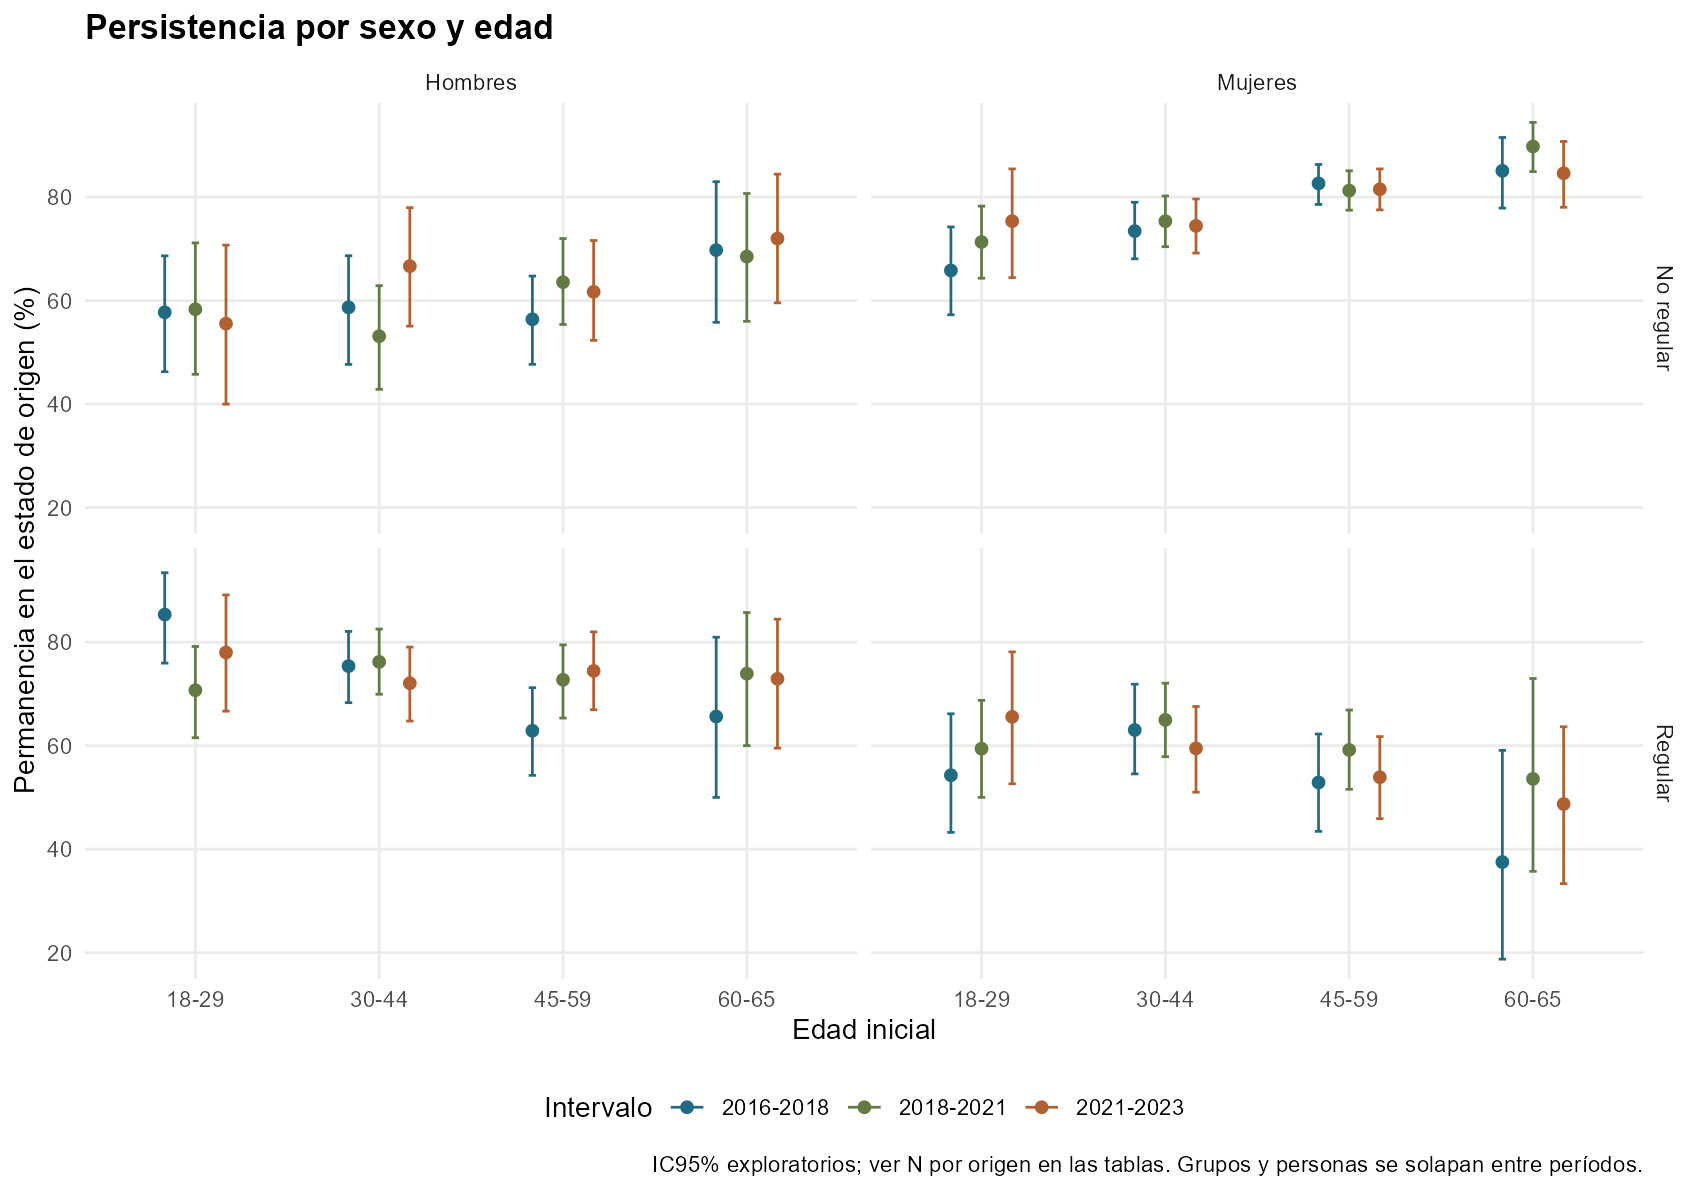

Elapsed: 0.01 minutes


In [9]:
#| label: elsoc-sex-age-plot
.t0 <- Sys.time()
z<-matrix_data[matrix_data$item=="s09"&matrix_data$from==matrix_data$to&grepl("^(Men|Women)_",matrix_data$group),]
z$Sexo<-ifelse(grepl("^Men",z$group),"Hombres","Mujeres");z$Edad<-sub("^(Men|Women)_","",z$group)
z$Origen<-ifelse(z$from==1,"Regular","No regular")
p<-ggplot2::ggplot(z,ggplot2::aes(x=Edad,y=100*estimate,color=interval,group=interval))+ggplot2::geom_point(position=ggplot2::position_dodge(.5),size=2)+ggplot2::geom_errorbar(ggplot2::aes(ymin=100*lower,ymax=100*upper),position=ggplot2::position_dodge(.5),width=.12)+ggplot2::facet_grid(Origen~Sexo)+ggplot2::scale_color_manual(values=c("#216A83","#637A44","#B16031"))+ggplot2::labs(x="Edad inicial",y="Permanencia en el estado de origen (%)",color="Intervalo",title="Persistencia por sexo y edad",caption="IC95% exploratorios; ver N por origen en las tablas. Grupos y personas se solapan entre períodos.")+plot_theme()
show_plot(p,"sex_age_persistence",height=7)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


## Muestras y educación completada aproximada

Se usa `m01_w01`, `m01_w03` o `m01_w05` según origen. La pregunta refiere nivel actual si estudia y último aprobado si no: no certifica título. Correspondencia H bajo supuestos: básica o menos={1,2,3,4}; media={5,6,8}; superior={7,9,10}; desconocido separado. Se supone completitud del nivel previo al cursar uno superior; posgrado no certifica título de posgrado completado. Pierde años, rama y condición de estudiante. No se usa la agrupación descriptiva distinta del manual (1:3/4:5/6:7/8:10), que corresponde a nivel alcanzado.

Se ofrecen márgenes educativos por período, con N e intervalos, sin modelo de interacción. [Soporte sexo×edad×educación y celdas pequeñas](__andres_control/elsoc_2021_2023_exploration/intervals/education_joint_support.csv); códigos originales y faltantes permanecen en la auditoría. No se fuerza equivalencia exacta con educación EPS/TSM.

In [10]:
#| label: elsoc-margins
.t0 <- Sys.time()
for(period in periods){
  z<-change_data[change_data$interval==period&grepl("^M[12]$|^Education_",change_data$group),]
  rows<-lapply(unique(z$group),function(g){a<-z[z$group==g&z$item=="s09"&z$event=="same",];b<-z[z$group==g&z$item=="s10",];data.frame(Grupo=group_label(g),N_S09=a$n_origin,S09_igual=ci(a),N_S10=b$n_origin[1],S10_igual=ci(b[b$event=="same",]),S10_aumenta=ci(b[b$event=="increase",]),S10_disminuye=ci(b[b$event=="decrease",]))})
  show_table(do.call(rbind,rows),paste(period,"márgenes de muestra y educación basal"))
}
show_table(read_table("education_joint_support"),"Soporte conjunto; no se ajusta modelo sexo × edad × educación")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Grupo,N_S09,S09_igual,N_S10,S10_igual,S10_aumenta,S10_disminuye
M1,1888,69.7% [67.5%; 71.7%],438,33.1% [28.9%; 37.5%],29.7% [25.4%; 33.9%],37.2% [32.7%; 41.6%]
M2,0,— [sin IC] *,0,— [sin IC] *,— [sin IC] *,— [sin IC] *
Básica o menos,622,71.5% [68.2%; 75.0%],127,38.6% [29.9%; 47.5%],27.6% [19.5%; 35.5%],33.9% [26.0%; 42.0%]
Media,783,70.9% [67.7%; 74.0%],179,32.4% [25.2%; 39.7%],27.4% [21.1%; 33.7%],40.2% [33.2%; 47.4%]
Superior,482,65.1% [60.8%; 69.3%],132,28.8% [21.0%; 36.6%],34.8% [26.4%; 44.0%],36.4% [27.6%; 45.0%]
Desconocida,1,100.0% [sin IC] *,0,— [sin IC] *,— [sin IC] *,— [sin IC] *


Grupo,N_S09,S09_igual,N_S10,S10_igual,S10_aumenta,S10_disminuye
M1,1367,73.1% [70.8%; 75.3%],394,30.5% [26.3%; 34.8%],39.1% [34.1%; 44.0%],30.5% [26.1%; 34.8%]
M2,894,68.9% [65.7%; 72.0%],237,32.9% [27.4%; 38.9%],42.2% [35.5%; 49.1%],24.9% [19.1%; 31.4%]
Básica o menos,631,73.2% [70.0%; 76.4%],139,41.0% [33.1%; 50.0%],28.8% [20.9%; 36.2%],30.2% [22.2%; 38.5%]
Media,1019,70.0% [67.3%; 72.6%],290,30.7% [25.5%; 36.3%],43.1% [37.1%; 48.8%],26.2% [21.2%; 31.5%]
Superior,610,72.0% [68.4%; 75.2%],202,25.7% [19.9%; 31.6%],44.1% [37.3%; 51.1%],30.2% [23.5%; 37.1%]
Desconocida,1,100.0% [sin IC] *,0,— [sin IC] *,— [sin IC] *,— [sin IC] *


Grupo,N_S09,S09_igual,N_S10,S10_igual,S10_aumenta,S10_disminuye
M1,1127,71.2% [68.6%; 73.7%],314,31.8% [26.8%; 37.1%],32.2% [27.3%; 37.2%],36.0% [30.5%; 41.4%]
M2,669,70.9% [67.4%; 74.1%],188,33.0% [26.4%; 40.3%],31.9% [25.3%; 38.5%],35.1% [28.3%; 41.6%]
Básica o menos,513,72.7% [69.0%; 76.2%],117,35.9% [27.6%; 44.6%],39.3% [30.5%; 48.3%],24.8% [17.1%; 33.3%]
Media,771,71.2% [68.0%; 74.4%],218,36.7% [30.1%; 43.6%],29.4% [23.0%; 35.7%],33.9% [27.3%; 40.5%]
Superior,512,69.1% [65.0%; 73.2%],167,24.0% [17.6%; 30.5%],30.5% [23.8%; 37.7%],45.5% [37.9%; 53.6%]
Desconocida,0,— [sin IC] *,0,— [sin IC] *,— [sin IC] *,— [sin IC] *


interval,sex,age_group,education,n_s09,n_s10,small_s09,small_s10
2016-2018,Men,18-29,Basic_or_less,25,12,TRUE,TRUE
2016-2018,Men,18-29,Secondary,80,33,FALSE,FALSE
2016-2018,Men,18-29,Higher,41,16,FALSE,TRUE
2016-2018,Men,18-29,Unknown,0,0,TRUE,TRUE
2016-2018,Men,30-44,Basic_or_less,41,21,FALSE,TRUE
2016-2018,Men,30-44,Secondary,98,41,FALSE,FALSE
2016-2018,Men,30-44,Higher,87,37,FALSE,FALSE
2016-2018,Men,30-44,Unknown,0,0,TRUE,TRUE
2016-2018,Men,45-59,Basic_or_less,108,34,FALSE,FALSE
2016-2018,Men,45-59,Secondary,90,30,FALSE,FALSE


Elapsed: 0.00 minutes


## Sensibilidad de calidad

Se conserva la misma regla primaria en los tres intervalos. Excluir discordancias edad–fecha no altera los patrones globales principales, pero reduce considerablemente soporte en el último par. La tabla muestra tamaño y permanencia por especificación; todas las direcciones están en el CSV de sensibilidad.

In [11]:
#| label: elsoc-sensitivity
.t0 <- Sys.time()
z<-read_table("quality_sensitivity");z<-z[z$event=="same",]
show_table(data.frame(Intervalo=z$interval,Especificación=z$scope,Indicador=z$item,N=z$n,Permanencia=pct(z$proportion)),"Comparación de reglas de calidad y cuestionarios completos")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


Intervalo,Especificación,Indicador,N,Permanencia
2016-2018,all_linked_no_quality_exclusion,s09,1907,69.5%
2016-2018,all_linked_no_quality_exclusion,s10,441,33.1%
2016-2018,primary_quality,s09,1888,69.7%
2016-2018,primary_quality,s10,438,33.1%
2016-2018,strict_age_consistency,s09,1693,69.7%
2016-2018,strict_age_consistency,s10,393,33.6%
2016-2018,primary_complete_questionnaires,s09,1888,69.7%
2016-2018,primary_complete_questionnaires,s10,438,33.1%
2018-2021,all_linked_no_quality_exclusion,s09,2266,71.4%
2018-2021,all_linked_no_quality_exclusion,s10,632,31.5%


Elapsed: 0.00 minutes


## Dependencia entre pares

Los 5.945 pares S09 pertenecen a **2.886 personas únicas**: 871 aportan un intervalo, 971 dos y 1.044 los tres. Los 1.571 pares S10 corresponden a **988 personas**: 544 aportan uno, 305 dos y 139 tres. Los N de los períodos no se suman como individuos independientes. [Contribuciones](__andres_control/elsoc_2021_2023_exploration/intervals/person_contributions.csv), [solapamiento entre períodos](__andres_control/elsoc_2021_2023_exploration/intervals/person_overlap.csv).

No se calcula una matriz conjunta ni una prueba de igualdad entre períodos: mezclaría duraciones, modos, cohortes y dominios. Si se plantea un contraste conjunto posterior, debe preservar todos los pares de cada persona y el conglomerado compartido en cada réplica, y definir la ponderación de períodos/personas; los intervalos marginales de este informe no sirven para una prueba independiente entre matrices. Esta decisión evita tratar las 5.945 observaciones como 5.945 personas.

In [12]:
#| label: elsoc-overlap
.t0 <- Sys.time()
z<-read_table("person_contributions");show_table(z[z$n_intervals>0,],"Personas según cantidad de intervalos aportados")
z<-read_table("person_overlap");show_table(z[z$item%in%c("s09","s10")&z$interval_a<=z$interval_b,],"Personas compartidas entre períodos; diagonal = N del indicador")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


item,n_intervals,n_people
s09,1,871
s09,2,971
s09,3,1044
s10,1,544
s10,2,305
s10,3,139
primary,1,862
primary,2,976
primary,3,1062


item,interval_a,interval_b,n_same_people
s09,2016-2018,2016-2018,1888
s09,2016-2018,2018-2021,1339
s09,2016-2018,2021-2023,1045
s09,2018-2021,2018-2021,2261
s09,2018-2021,2021-2023,1719
s09,2021-2023,2021-2023,1796
s10,2016-2018,2016-2018,438
s10,2016-2018,2018-2021,240
s10,2016-2018,2021-2023,139
s10,2018-2021,2018-2021,631


Elapsed: 0.00 minutes


## Triangulación y conclusión

La repetición de persistencia cercana al 70% dentro de ELSOC y del contraste joven/mayor en mujeres aporta evidencia descriptiva de estabilidad y heterogeneidad. La reversión del balance de frecuencia advierte contra transportar una única dirección temporal al ciclo anual de MiCSim. No identifica la causa de diferencias entre períodos.

Se conserva el [mapa operativo ELSOC/EPS/TSM](_elsoc/README.md): S09 regularidad es **no comparable** con cualquier consumo EPS (`f13_1…3`) o TSM (`e3a1`), volumen o HED. Frecuencia ELSOC son días de cualquier bebida entre regulares; EPS `f14_1…3` mide por bebida (no sumar días por simultaneidad); TSM `e3a1` son veces habituales en bandas, sin la misma ventana. Una categoría común más amplia exige supuestos explícitos y pierde información; no se implementó aquí. S09/S10 no permiten AUDIT ni historia vitalicia.

El patrón de mayor persistencia de no regularidad en mujeres mayores es cualitativamente compatible con la permanencia de no consumo observado TSM revisada anteriormente, pero son estados distintos, con otros pesos y lapsos de aproximadamente 4–8 meses. Los contrastes EPS existentes también son plurianuales y no miden regularidad. Se reutiliza su contexto previo, sin recalcular motores ni comparar porcentajes como si fueran la misma escala. S15 2023 permanece descrita aparte en el informe anterior; no rescata volumen habitual ni un enlace de cantidad para estos tres pares.

**Conclusión:** hay evidencia repetida de persistencia de regularidad y heterogeneidad por grupos, pero no una dirección estable de cambio de frecuencia entre períodos. Los tres pares permiten triangulación exploratoria; no validan la transición anual de estados EPS. Antes de ponderar o calibrar: resolver pesos por par, modo individual/CATI 2023, coherencia de edad/fecha y cualquier definición común EPS/TSM. Si estos datos se usan para ajustar el motor, no serán evaluación independiente de ese mismo ajuste.

## Fuentes y verificación

- [Repositorio oficial manual-elsoc](https://github.com/elsoc-coes/manual-elsoc/), versión documental [edd00962c2e7df86ccf90f28bf9fc7fade186b37](https://github.com/elsoc-coes/manual-elsoc/commit/edd00962c2e7df86ccf90f28bf9fc7fade186b37). [Listado global](https://github.com/elsoc-coes/manual-elsoc/blob/edd00962c2e7df86ccf90f28bf9fc7fade186b37/inputs/0A_Listado_Variables_Global_ELSOC_v2023.xlsx), cotejado con CSV local y etiquetas SAV.
- [2018 M1](https://coes.cl/wp-content/uploads/2025/08/3_Cuestionario_Ola_3_Muestra_Original.pdf), p.22; [2018 M2](https://coes.cl/wp-content/uploads/2025/08/3_Cuestionario_Ola_3_Muestra_Refresco.pdf), p.23. Educación pp.24/25.
- [2021 M1 llamado A](https://coes.cl/wp-content/uploads/2025/08/5_Cuestionario_Ola_5_Muestra_Original_llamado_A.pdf), p.7; [M2 llamado A](https://coes.cl/wp-content/uploads/2025/08/5_Cuestionario_Ola_5_Muestra_Refresco_llamado_A.pdf), p.10. [2023, hojas CAPI M1/M2](https://github.com/elsoc-coes/manual-elsoc/blob/edd00962c2e7df86ccf90f28bf9fc7fade186b37/inputs/cuestionario_2023_v18.xlsx).
- [Manual metodológico](https://github.com/elsoc-coes/manual-elsoc/blob/edd00962c2e7df86ccf90f28bf9fc7fade186b37/manual-metodologico-elsoc-english.Rmd); [diseño y pesos transversales](https://manual-metodologico-elsoc.netlify.app/dis_ponderadores); [informe longitudinal](https://pondedradores-long-elsoc.netlify.app/), antecedente hasta 2022 ya revisado, no releído íntegramente en esta ampliación por límite de tamaño web.

Ejecutar desde la raíz `Rscript __andres_control/elsoc_2021_2023_exploration/extend_intervals.R`, o el notebook de arriba con kernel R/renv del proyecto. Los microdatos se leen de `_elsoc/elsoc_wide_2016_2023.tar.xz.enc` mediante `acc_data()`, descifrando solo en `tempdir()`; se requiere `ACC_DATA_KEY` local. Únicamente agregados exportados; original externo intacto. Fuente única: SAV ancho MD5 `dac64998f382fc99a5688ee8b5947db3`; comprobación automática de que coincide con el análisis anterior. Se verifica por hash que las tablas anteriores no cambian, y por recuento independiente que las 68 celdas globales S09/S10 del último par reproducen sus conteos. [Comprobaciones](__andres_control/elsoc_2021_2023_exploration/intervals/validation.csv), [sesión R](__andres_control/elsoc_2021_2023_exploration/intervals/session_info.txt). No se modificaron motores ni notebooks originales.

In [13]:
#| label: elsoc-validation
.t0 <- Sys.time()
validation<-read_table("validation");stopifnot(all(validation$passed))
show_table(validation,"Comprobaciones ejecutadas sobre datos reales y resultados reutilizados")
for(item in c("s09","s10")){
  x<-read_table("person_contributions");x<-x[x$item==item,]
  stopifnot(sum(x$n_intervals*x$n_people)==sum(change_data$n_origin[change_data$group=="All"&change_data$item==item&change_data$event=="same"]))
}
cat("Original engines and notebooks were not executed or edited. No pooled independent-person inference.\n")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units="mins"))))


check,passed
unique_longitudinal_ids,TRUE
valid_codes_all_waves,TRUE
s10_no_valid_for_nonregular,TRUE
matrix_rows_sum_one,TRUE
last_pair_counts_match,TRUE
existing_tables_unchanged,TRUE
no_pooled_independence_assumption,TRUE


Original engines and notebooks were not executed or edited. No pooled independent-person inference.


Elapsed: 0.00 minutes
